# Pembersihan Katalog Gempa BMKG

Notebook ini mendokumentasikan langkah `python -m gempa.clean` (modul `src/gempa/`):

1. **Homogenisasi magnitudo ke Mw** dengan relasi Taruna & Pratiwi (2021), diuji pada pasangan Mw di katalog ini.
2. **Magnitude of completeness (Mc)** per tahun, metode maximum curvature + 0,2.
3. **Kualitas data:** kedalaman default, lokasi kurang terikat, dan event semu.
4. **Declustering** Gardner & Knopoff (1974) untuk memisahkan gempa utama dan susulan.
5. **Intensitas per event** (Gutenberg–Richter 1956) dan kelas MMI, dibandingkan dengan label K-Means.

**Referensi**
- Taruna, R. M. & Pratiwi, A. (2021). Konversi Empiris Summary Magnitude, Local Magnitude, Body-Wave Magnitude, Surface Magnitude, dan Moment Magnitude Menggunakan Data Gempabumi 1922–2020 di Nusa Tenggara Barat. *Jurnal Sains Teknologi & Lingkungan*, 7(1), 1–12. https://doi.org/10.29303/jstl.v7i1.198
- Pusgen (2017). *Peta Sumber dan Bahaya Gempa Indonesia Tahun 2017*.
- Gardner, J. K. & Knopoff, L. (1974). Is the sequence of earthquakes in Southern California, with aftershocks removed, Poissonian? *BSSA*, 64(5), 1363–1367.
- Wiemer, S. & Wyss, M. (2000). Minimum magnitude of completeness in earthquake catalogs. *BSSA*, 90(4), 859–869.
- Woessner, J. & Wiemer, S. (2005). Assessing the quality of earthquake catalogues. *BSSA*, 95(2), 684–698.
- Gutenberg, B. & Richter, C. F. (1956). Earthquake magnitude, intensity, energy, and acceleration. *BSSA*, 46(2), 105–145.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent / "src"))

from gempa import paths
from gempa.clean import clean_catalog
from gempa.completeness import mc_maxc
from gempa.data import load_catalog
from gempa.decluster import gardner_knopoff
from gempa.intensity import MMI_CLASSES
from gempa.magnitude import CONVERSIONS
from gempa.train import FEATURES, build_pipeline, summarize_clusters

raw = load_catalog(paths.RAW_CATALOG)
df, report = clean_catalog(raw)
print(f"{report['n_raw']:,} event mentah -> {report['n_clean']:,} event bersih")

131,131 event mentah -> 131,131 event bersih


## 1. Homogenisasi Magnitudo ke Mw

In [2]:
types = (
    df.groupby("mag_type")
    .agg(jumlah=("mag", "size"), mag_min=("mag", "min"), mag_median=("mag", "median"), mag_max=("mag", "max"),
         metode=("mw_method", "first"), di_luar_rentang=("mw_extrapolated", "sum"))
    .sort_values("jumlah", ascending=False)
    .round(2)
)
display(types)
display(pd.DataFrame(
    [{"tipe": t, "relasi": f"Mw = {s} * {t} {i:+}", "rentang valid": f"{lo}–{hi}", "sumber": src}
     for t, (s, i, (lo, hi), src) in CONVERSIONS.items()]
))

,jumlah,mag_min,mag_median,mag_max,metode,di_luar_rentang
mag_type,,,,,,
MLv,63508,0.19,3.30,6.59,conversion,19821
M,59044,0.64,3.48,7.29,conversion,14024
mb,4629,3.19,4.75,7.02,conversion,15
Mw,2223,2.65,4.61,7.52,native,0
Mw(mB),1546,3.32,5.12,7.90,native,0
ML,162,0.83,3.20,4.49,conversion,4
mB,10,4.62,5.40,7.01,approx,0
Mwp,5,5.46,5.63,7.11,native,0
Mjma,4,2.45,3.73,4.15,approx,0


,tipe,relasi,rentang valid,sumber
0,M,Mw = 1.0166 * M -0.2207,2.93–7.16,Taruna & Pratiwi (2021)
1,MLv,Mw = 0.7353 * MLv +1.0722,2.93–7.57,Taruna & Pratiwi (2021)
2,ML,Mw = 0.6424 * ML +1.5595,1.75–7.82,Taruna & Pratiwi (2021)
3,mb,Mw = 1.1993 * mb -1.2261,3.67–6.99,Taruna & Pratiwi (2021)


### Validasi relasi pada katalog ini

Sebanyak 3.905 event juga punya magnitudo dari solusi mekanisme fokal (`magFM`); 1.692 di antaranya bertipe **Mw**.
Pasangan ini dipakai untuk menguji relasi konversi: Taruna & Pratiwi (2021), regresi OLS dari data ini sendiri,
Pusgen (2017) untuk mb, dan tanpa konversi (identitas).

,tipe,n,rentang,Taruna 2021 (RMSE / bias),OLS data sendiri (RMSE / bias),Pusgen 2017 (RMSE / bias),Identitas (RMSE / bias)
0,M,440,2.5–7.1,0.343 / -0.016,0.309 / -0.000 [Mw = 0.730x +1.119],-,0.374 / -0.158
1,MLv,353,2.5–5.8,0.393 / -0.015,0.372 / -0.000 [Mw = 0.466x +2.244],-,0.462 / -0.108
2,mb,249,4.4–6.3,0.308 / +0.020,0.303 / -0.000 [Mw = 1.034x -0.365],0.444 / -0.325,0.358 / -0.190


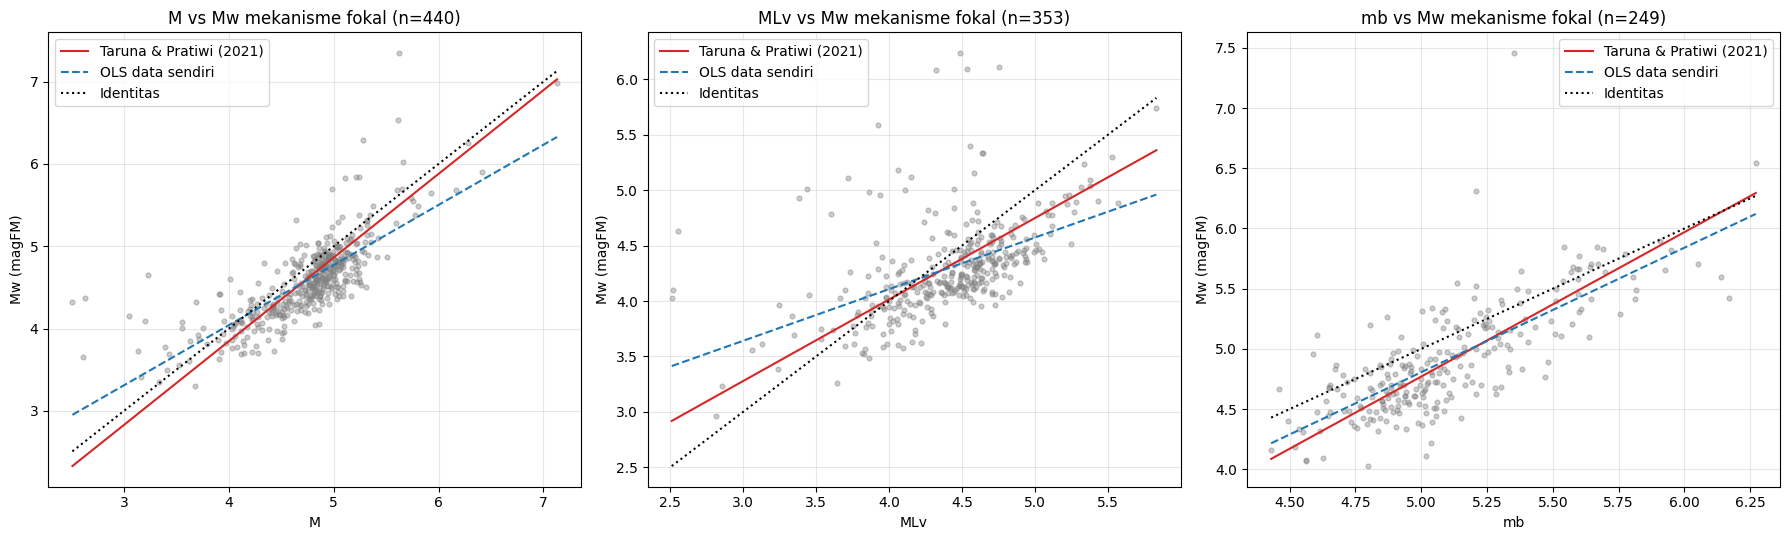

In [3]:
pairs = raw[(raw["magTypeFM"] == "Mw") & raw["magFM"].notna()].copy()
pairs["mw_fm"] = pd.to_numeric(pairs["magFM"])
PUSGEN_MB = (1.0107, 0.0801)

def stats(residual):
    return f"{np.sqrt(np.mean(residual ** 2)):.3f} / {np.mean(residual):+.3f}"

rows, fits = [], {}
for mtype in ["M", "MLv", "mb"]:
    g = pairs[pairs["mag_type"] == mtype]
    x, y = g["mag"].to_numpy(), g["mw_fm"].to_numpy()
    slope, intercept, *_ = CONVERSIONS[mtype]
    b, a = np.polyfit(x, y, 1)
    fits[mtype] = (x, y, slope, intercept, b, a)
    rows.append({
        "tipe": mtype, "n": len(g), "rentang": f"{x.min():.1f}–{x.max():.1f}",
        "Taruna 2021 (RMSE / bias)": stats(y - (slope * x + intercept)),
        "OLS data sendiri (RMSE / bias)": stats(y - (b * x + a)) + f"  [Mw = {b:.3f}x {a:+.3f}]",
        "Pusgen 2017 (RMSE / bias)": stats(y - (PUSGEN_MB[0] * x + PUSGEN_MB[1])) if mtype == "mb" else "-",
        "Identitas (RMSE / bias)": stats(y - x),
    })
display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (mtype, (x, y, slope, intercept, b, a)) in zip(axes, fits.items()):
    grid = np.linspace(x.min(), x.max(), 50)
    ax.scatter(x, y, s=12, alpha=0.4, color="gray")
    ax.plot(grid, slope * grid + intercept, color="tab:red", label="Taruna & Pratiwi (2021)")
    ax.plot(grid, b * grid + a, color="tab:blue", linestyle="--", label="OLS data sendiri")
    ax.plot(grid, grid, color="black", linestyle=":", label="Identitas")
    ax.set_title(f"{mtype} vs Mw mekanisme fokal (n={len(x)})")
    ax.set_xlabel(mtype)
    ax.set_ylabel("Mw (magFM)")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

**Kesimpulan konversi:** relasi Taruna & Pratiwi (2021) hampir tanpa bias pada data ini (|bias| ≤ 0,02), dengan RMSE hanya
sedikit di atas regresi lokal. Regresi lokal tidak dipakai karena pasangan datanya terbatas pada rentang sempit
(mis. MLv hanya sampai ±5,8) dan didominasi gempa yang cukup besar untuk punya solusi mekanisme fokal.
Tanpa konversi, M, MLv, dan mb rata-rata lebih kecil 0,11–0,19 dari Mw. Relasi Pusgen (2017) untuk mb bias −0,33 pada data ini.
Event di luar rentang valid relasi (terutama gempa sangat kecil) ditandai `mw_extrapolated`.

## 2. Magnitude of Completeness (Mc)

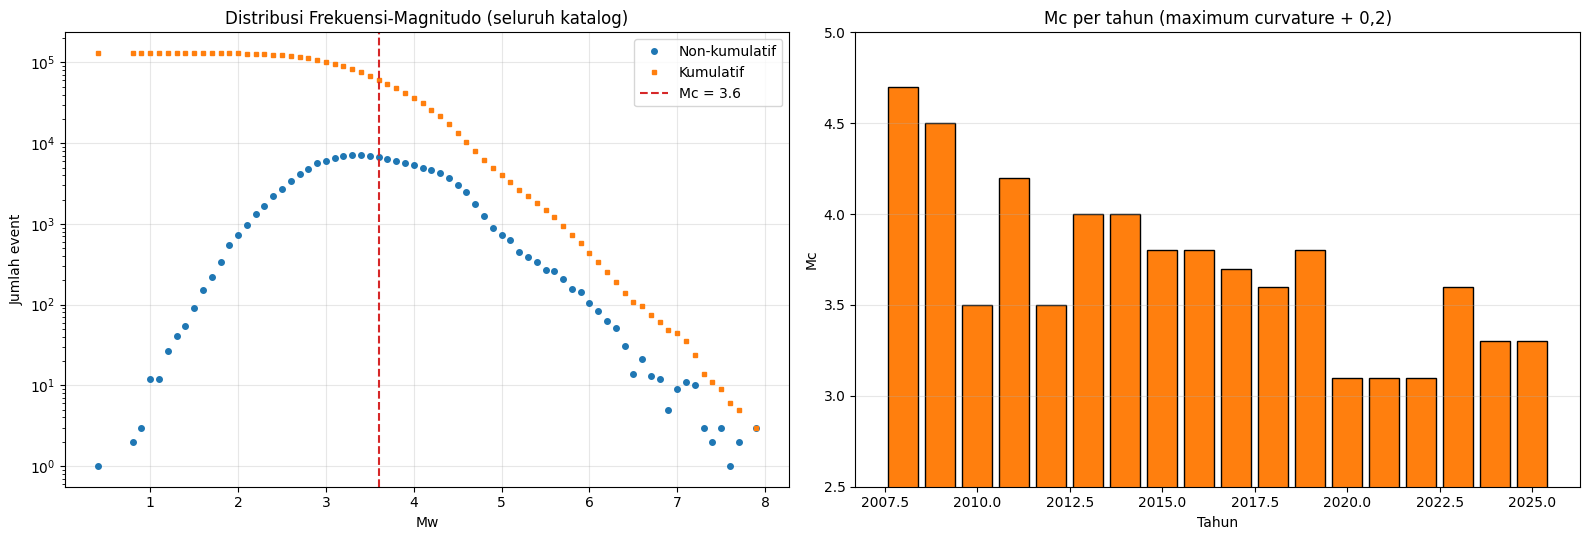

Event dengan Mw >= Mc tahunannya: 60,266 dari 131,131


In [4]:
mc_table = pd.DataFrame(report["completeness"]["by_year"])
mc_overall = report["completeness"]["mc_overall"]

bins = np.round(df["mw"] / 0.1) * 0.1
fmd = bins.value_counts().sort_index()
cumulative = fmd[::-1].cumsum()[::-1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))
ax1.semilogy(fmd.index, fmd.values, "o", ms=4, label="Non-kumulatif")
ax1.semilogy(cumulative.index, cumulative.values, "s", ms=3, label="Kumulatif")
ax1.axvline(mc_overall, color="tab:red", linestyle="--", label=f"Mc = {mc_overall}")
ax1.set_xlabel("Mw")
ax1.set_ylabel("Jumlah event")
ax1.set_title("Distribusi Frekuensi-Magnitudo (seluruh katalog)")
ax1.grid(alpha=0.3)
ax1.legend()

ax2.bar(mc_table["year"], mc_table["mc"], color="tab:orange", edgecolor="black")
ax2.set_ylim(2.5, mc_table["mc"].max() + 0.3)
ax2.set_xlabel("Tahun")
ax2.set_ylabel("Mc")
ax2.set_title("Mc per tahun (maximum curvature + 0,2)")
ax2.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Event dengan Mw >= Mc tahunannya: {df['above_mc'].sum():,} dari {len(df):,}")

Mc turun dari ±4,5 (2008–2009) ke ±3,1 (2020–2022) seiring berkembangnya jaringan seismograf BMKG.
Karena itu statistik laju gempa sebaiknya hanya memakai event dengan Mw ≥ Mc tahunannya (`above_mc`).

## 3. Kualitas Data

In [5]:
quality = pd.Series({
    "Kedalaman default (0 atau 10 km)": report["depth_fixed"],
    "Lokasi kurang terikat (gap > 180° atau < 5 fase)": report["low_quality_location"],
    "Event semu (Mw >= 5, < 10 fase, gap > 180°)": report["suspect_event"],
}, name="jumlah event")
display(quality.to_frame())

suspect = raw.set_index("eventID").loc[df.loc[df["suspect_event"], "eventID"]]
display(
    suspect.assign(mw=df.set_index("eventID")["mw"])
    .nlargest(10, "mw")[["time", "mag", "mag_type", "mw", "phasecount", "azimuth_gap", "location"]]
    .round({"mag": 2, "mw": 2, "azimuth_gap": 1})
)

big = df[df["mw"] >= 5].assign(year=df["time"].dt.year)
big = big.merge(raw[["eventID", "phasecount"]], on="eventID", suffixes=("", "_raw"))
print("Median jumlah fase gempa Mw >= 5 per tahun:")
print(big.groupby("year")["phasecount"].median().to_dict())

,jumlah event
Kedalaman default (0 atau 10 km),45711
Lokasi kurang terikat (gap > 180° atau < 5 fase),42793
"Event semu (Mw >= 5, < 10 fase, gap > 180°)",254


,time,mag,mag_type,mw,phasecount,azimuth_gap,location
eventID,,,,,,,
bmg2019mgdc,2019-06-24 02:48:07.049203+00:00,7.45,Mw,7.45,6.0,340.2,"Irian Jaya, Indonesia"
bmg2019wikz,2019-11-14 16:25:25.806571+00:00,7.20,M,7.10,4.0,208.5,"Seram, Indonesia"
bmg2020icjb,2020-04-25 03:07:34.125117+00:00,7.00,Mw,7.00,8.0,280.2,"North of Halmahera, Indonesia"
bmg2021jeer,2021-05-11 08:44:27.259695+00:00,7.03,M,6.93,8.0,348.6,"Southwest of Sumatra, Indonesia"
bmg2020zikx,2020-12-26 08:59:18.082667+00:00,6.76,M,6.65,9.0,202.9,South China Sea
bmg2019ywfu,2019-12-20 16:46:44.595576+00:00,6.74,M,6.63,6.0,202.8,Flores Sea
bmg2008yxzw,2008-12-20 21:32:20.729454+00:00,6.46,mb,6.53,7.0,235.9,"Talaud Islands, Indonesia"
bmg2019wjms,2019-11-15 06:25:53.803732+00:00,6.64,M,6.53,8.0,302.5,Borneo
bmg2009tdlh,2009-09-30 10:29:27.257577+00:00,6.41,mb,6.46,8.0,220.5,South China Sea


Median jumlah fase gempa Mw >= 5 per tahun:
{2008: 56.0, 2009: 48.0, 2010: 93.0, 2011: 73.5, 2012: 97.0, 2013: 66.5, 2014: 111.5, 2015: 119.0, 2016: 130.0, 2017: 61.0, 2018: 55.0, 2019: 11.0, 2020: 10.0, 2021: 10.0, 2022: 236.0, 2023: 213.0, 2024: 202.0, 2025: 176.0}


Contoh event semu: `bmg2019wikz` "Seram M7,2" hanya punya 4 fase dengan celah azimut 208°, muncul 8 menit setelah gempa
nyata M7,1 di Laut Maluku. Window declustering yang besar dari event seperti ini menyerap seluruh sekuens gempa Ambon 2019.

Jumlah fase saja tidak bisa dipakai sebagai kriteria: median fase seluruh gempa Mw ≥ 5 tahun 2019–2021 hanya ±10
(perubahan cara pencatatan), sehingga kriteria event semu menggabungkan Mw ≥ 5, < 10 fase, **dan** celah azimut > 180°.
Event semu tetap disimpan dengan flag `suspect_event`, tetapi tidak ikut declustering dan disembunyikan secara default di aplikasi.

**Celah data:** gempa Lombok M6,4 (29 Juli 2018) dan M6,9 (5 Agustus 2018) tidak ada di katalog ini.

In [6]:
window = df[(df["time"] >= "2018-07-28") & (df["time"] < "2018-08-21")
            & df["latitude"].between(-9.3, -7.3) & df["longitude"].between(115.5, 117.5)]
print(f"Event di sekitar Lombok, 28 Jul - 20 Agu 2018: {len(window)}, Mw maksimum: {window['mw'].max():.2f}")

Event di sekitar Lombok, 28 Jul - 20 Agu 2018: 1236, Mw maksimum: 5.11


## 4. Declustering Gardner & Knopoff (1974)

Gempa utama   : 49,632
Gempa susulan : 81,245
Event semu (tidak ikut declustering): 254
Gempa utama bila window simetris (foreshock + aftershock): 32,506
Proporsi gempa utama di atas Mc: 42.9%


,eventID,time,mw,location,n_events
0,bmg2019svqk,2019-09-25T23:46:44.673309+00:00,6.46,"Seram, Indonesia",1072
1,bmg2017klni,2017-05-29T14:35:27.497805+00:00,6.63,"Sulawesi, Indonesia",1042
2,bmg2019wiks,2019-11-14T16:17:42.991642+00:00,7.15,Northern Molucca Sea,858
3,bmg2019hdky,2019-04-12T11:40:50.439722+00:00,6.78,"Sulawesi, Indonesia",739
4,bmg2021ykge,2021-12-14T03:20:23.200204+00:00,7.43,Flores Sea,658
5,bmg2025ebba,2025-02-27T11:47:57.189494+00:00,4.53,"Sulawesi, Indonesia",594
6,bmg2014wjez,2014-11-15T02:31:44.119639+00:00,7.03,Northern Molucca Sea,587
7,bmg2023bfnq,2023-01-18T06:06:16.115854+00:00,7.22,Northern Molucca Sea,562
8,bmg2023bfcs,2023-01-18T00:34:46.442015+00:00,6.32,"Minahassa Peninsula, Sulawesi",555
9,bmg2019nevb,2019-07-07T15:08:42.016671+00:00,6.97,Northern Molucca Sea,472


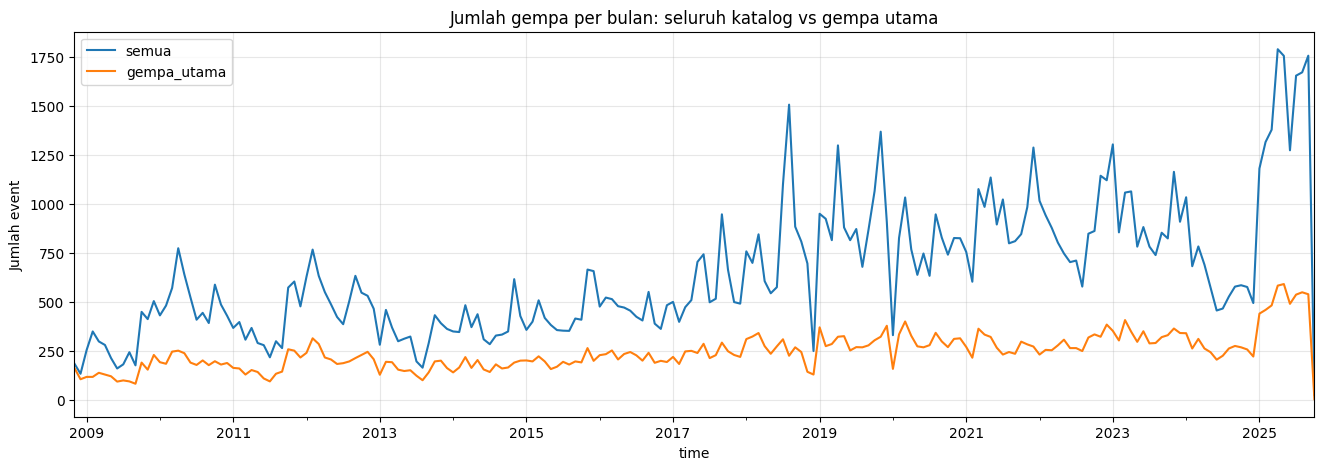

In [7]:
dec = report["declustering"]
print(f"Gempa utama   : {dec['mainshocks']:,}")
print(f"Gempa susulan : {dec['dependent']:,}")
print(f"Event semu (tidak ikut declustering): {dec['excluded_suspect']:,}")
print(f"Gempa utama bila window simetris (foreshock + aftershock): {dec['mainshocks_symmetric_window']:,}")
print(f"Proporsi gempa utama di atas Mc: {df.loc[df['above_mc'] & ~df['suspect_event'], 'is_mainshock'].mean():.1%}")

display(pd.DataFrame(dec["largest_sequences"]))

monthly = df.set_index("time").resample("MS").agg(semua=("mw", "size"), gempa_utama=("is_mainshock", "sum"))
ax = monthly.plot(figsize=(16, 5), title="Jumlah gempa per bulan: seluruh katalog vs gempa utama")
ax.set_ylabel("Jumlah event")
ax.grid(alpha=0.3)
plt.show()

### Uji pada sekuens yang diketahui

Window aftershock (default) dibandingkan dengan window simetris. Dengan window simetris, gempa Cianjur 2022 (Mw 5,6)
terbaca sebagai *foreshock* dari event Mw 5,97 pada 8 Desember 2022, sehingga pipeline memakai window aftershock seperti metode aslinya.

In [8]:
real = df[~df["suspect_event"]]
_, main_sym = gardner_knopoff(real["time"], real["latitude"], real["longitude"], real["mw"], foreshock_ratio=1.0)
sym = pd.Series(main_sym, index=real.index)

known = {
    "Palu 2018": ("2018-09-28", 7.0),
    "Ambon 2019": ("2019-09-25", 6.4),
    "Laut Maluku 2019": ("2019-11-14", 7.0),
    "Cianjur 2022": ("2022-11-21", 5.5),
}
rows = []
for name, (date, min_mw) in known.items():
    day = df[(df["time"].dt.strftime("%Y-%m-%d") == date) & (df["mw"] >= min_mw)]
    event = day.loc[day["mw"].idxmax()]
    rows.append({
        "gempa": name, "eventID": event["eventID"], "Mw": round(event["mw"], 2), "lokasi": event["location"],
        "gempa utama (window aftershock)": bool(event["is_mainshock"]),
        "ukuran sekuens": int((df["sequence_id"] == event["eventID"]).sum()),
        "gempa utama (window simetris)": bool(sym.get(event.name, False)),
    })
display(pd.DataFrame(rows))

,gempa,eventID,Mw,lokasi,gempa utama (window aftershock),ukuran sekuens,gempa utama (window simetris)
0,Palu 2018,bmg2018tabs,7.52,"Minahassa Peninsula, Sulawesi",True,349,True
1,Ambon 2019,bmg2019svqk,6.46,"Seram, Indonesia",True,1072,True
2,Laut Maluku 2019,bmg2019wiks,7.15,Northern Molucca Sea,True,858,True
3,Cianjur 2022,bmg2022wulo,5.60,"Java, Indonesia",True,363,False


## 5. Intensitas per Event vs Label K-Means

Jumlah event per kelas MMI:
mmi_class
I-II      36745
III-IV    56430
V-VI      35012
VII+       2944
Name: count, dtype: int64


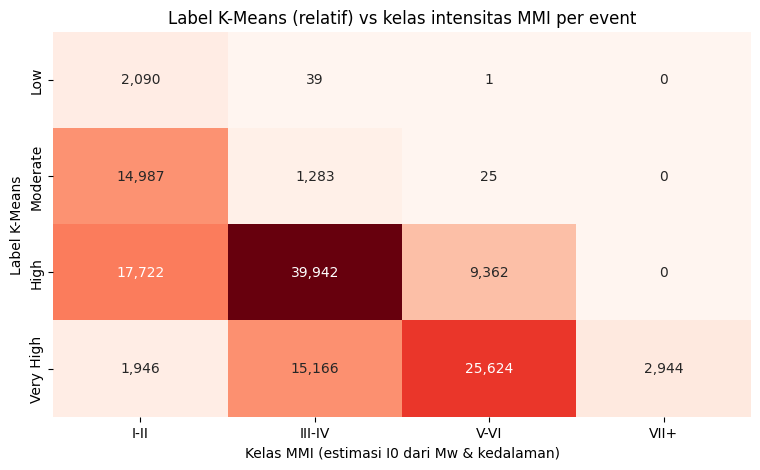

mmi_class,I-II,III-IV,V-VI,VII+
label,,,,
Low,98.1,1.8,0.0,0.0
Moderate,92.0,7.9,0.2,0.0
High,26.4,59.6,14.0,0.0
Very High,4.3,33.2,56.1,6.4


In [9]:
counts = df["mmi_class"].value_counts().reindex(MMI_CLASSES)
print("Jumlah event per kelas MMI:")
print(counts)

pipeline = build_pipeline(4).fit(df[FEATURES])
df["cluster"] = pipeline["kmeans"].labels_
summary = summarize_clusters(df)
df["label"] = df["cluster"].map(dict(zip(summary["cluster"], summary["label"])))

crosstab = pd.crosstab(df["label"], df["mmi_class"]).reindex(index=list(summary["label"]), columns=MMI_CLASSES)
plt.figure(figsize=(9, 5))
sns.heatmap(crosstab, annot=True, fmt=",d", cmap="Reds", cbar=False)
plt.title("Label K-Means (relatif) vs kelas intensitas MMI per event")
plt.xlabel("Kelas MMI (estimasi I0 dari Mw & kedalaman)")
plt.ylabel("Label K-Means")
plt.show()

display((crosstab.div(crosstab.sum(axis=1), axis=0) * 100).round(1))

**Temuan utama:** label K-Means tidak bisa dibaca sebagai tingkat risiko absolut.

- Lebih dari seperempat event berlabel **High** berintensitas **I–II** (tidak terasa).
- Label **Moderate** dan **Low** hampir seluruhnya I–II, karena berisi gempa menengah dan dalam.
- Hanya label **Very High** yang memuat intensitas VII+ (gempa dangkal dengan Mw besar).

Karena itu aplikasi memakai **kelas MMI per event** untuk warna, legenda, dan rekomendasi. Label K-Means
ditampilkan sebagai *profil klaster* (kombinasi magnitudo–kedalaman). Tahap berikutnya (zonasi seismik)
memakai katalog bersih ini: gempa utama, Mw ≥ Mc, tanpa event semu.